In [38]:
# Quiz : 
# 1. 도미, 빙어 구분하는 머신러닝을 구성(길이 21, 무게 90의 고기를 구분, 로지스틱회귀 알고리즘을 사용)
# 2. 도미, 빙어 길이와 무게의 산점도 그래프를 출력하시오.
# 3. 길이 25, 무게 150의 생선을 예측하시오.

In [2]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit

In [3]:
# [ 도미 ]
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# [ 빙어 ]
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [5]:
len(bream_length)
len(smelt_length)

14

In [6]:
# 데이터 전처리
# 도미, 빙어 데이터 합치기
length = bream_length+smelt_length
weight = bream_weight+smelt_weight
data = np.column_stack((length,weight))
label = ['bream']*35 + ['smelt'] * 14

In [7]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [8]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [9]:
# 학습
lr = LogisticRegression()
lr.fit(train_scaled,train_label)
print('-')

-


In [10]:
new = [[21,90]]
new2 = [[25,150]]

In [11]:
# in_data = input('생선의 길이,무게를 입력하세요.>> 예)21,90 ')
in_data = '21,9'
in_data = in_data.split(',')
in_data2 = list(map(float,in_data))
in_data2

[21.0, 9.0]

In [12]:
new_scaled = ss.transform([[21,90]])
new2_scaled = ss.transform([[25,150]])

In [13]:
result = lr.predict(new_scaled)
result2 = lr.predict(new2_scaled)
result[0]
p_result = lr.predict_proba(new_scaled)
p_result2 = lr.predict_proba(new2_scaled)
p_result[0][0]
print(f'예측생선 : {result[0]} / ({p_result[0][1]*100:.2f} %)')
print(f'예측생선 : {result2[0]} / ({p_result2[0][0]*100:.2f} %)')

예측생선 : smelt / (55.23 %)
예측생선 : bream / (67.84 %)


In [14]:
train_scaled[:,0]

array([ 0.37460577,  0.27666962,  0.34522492, -1.45680021, -1.40783213,
       -1.29030875,  0.57047806,  0.44316107,  0.66841421,  0.86428651,
        1.4519034 ,  1.20706303, -0.07590051, -1.3882449 ,  1.30499918,
        0.34522492,  1.06015881,  0.47254192, -1.53514913,  0.01224202,
        0.76635036,  0.03182925, -1.52535551, -1.60370443,  0.86428651,
       -1.46659382,  0.47254192,  0.81531843,  0.71738229, -1.09443646,
        0.76635036,  0.37460577, -1.40783213,  0.57047806,  0.96222266,
       -1.48618105])

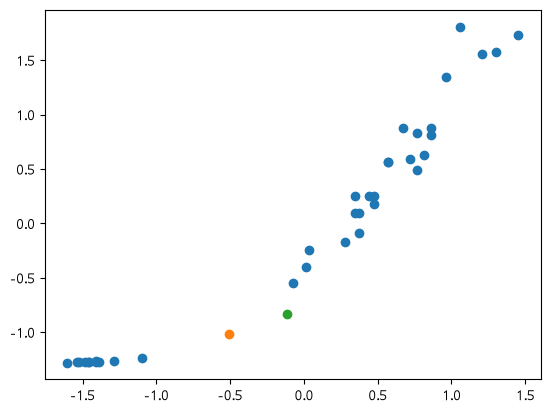

In [15]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1])
plt.scatter(new2_scaled[:,0],new2_scaled[:,1])
plt.show()


In [16]:
lr.predict_proba(test_scaled[:5])

array([[0.94088243, 0.05911757],
       [0.11387061, 0.88612939],
       [0.15599382, 0.84400618],
       [0.10985197, 0.89014803],
       [0.98807467, 0.01192533]])

In [17]:
decisions = lr.decision_function(test_scaled[:5])
np.round(decisions,decimals=4)
expit(decisions)

array([0.05911757, 0.88612939, 0.84400618, 0.89014803, 0.01192533])

In [18]:
print('train정확도 : ',lr.score(train_scaled,train_label))
print('test정확도 : ',lr.score(test_scaled,test_label))

train정확도 :  1.0
test정확도 :  1.0
